In [1]:
import os
os.chdir('/home/hedi/HSCNG/')
import numpy as np
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
from astropy import units as u
import matplotlib.pyplot as plt
import pprint
import pymaster as nmt
from hsc_y3_utils import stats_code
from hsc_y3_utils import map_utils

In [9]:
name_fields = ['XMM', 'VVDS','GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches= [8, 25,23,7,26,13] # of each corresponding field

field = 'GAMA09H'
tomo_bin = [1, 2, 3, 4]         # tomo_bin, 0 is excluded.

In [3]:
array2dict_norandom = lambda arr: {['ls', 'EE', 'EB', 'BB'][i]: arr[:,i] for i in range(arr.shape[1])}
array2dict_k = lambda arr: {['ls', 'EE', 'EB', 'BB', 'EE_rm', 'EE_std', 'EB_rm', 'EB_std', 'BB_rm', 'BB_std'][i]: arr[:,i] for i in range(arr.shape[1])}

In [10]:
stat_gg = array2dict_k(np.loadtxt(f'results/Cl_results_{field}_gg.txt'))
stat_k = [
    array2dict_k(np.loadtxt(f'results/Cl_results_{field}_inpainting-KSI-masking-smooth k.txt')),
    array2dict_k(np.loadtxt(f'results/Cl_results_{field}_KSI-masking-smooth k.txt')),
    array2dict_k(np.loadtxt(f'results/Cl_results_{field}_smooth g-inpainting-KSI-masking.txt')),
    array2dict_k(np.loadtxt(f'results/Cl_results_{field}_smooth g-KSI-masking.txt'))
]                                                               # ls, EE, EB, BB, EE_rm, EE_std, EB_rm, EB_std, BB_rm, BB_std

stat_k_mock = [
    array2dict_norandom(np.loadtxt(f'results/Cl_results_{field}_cone{i}_KSI-masking-smooth k.txt'))
    for i in range(1, 26)
]

# kk VS gg, with noise

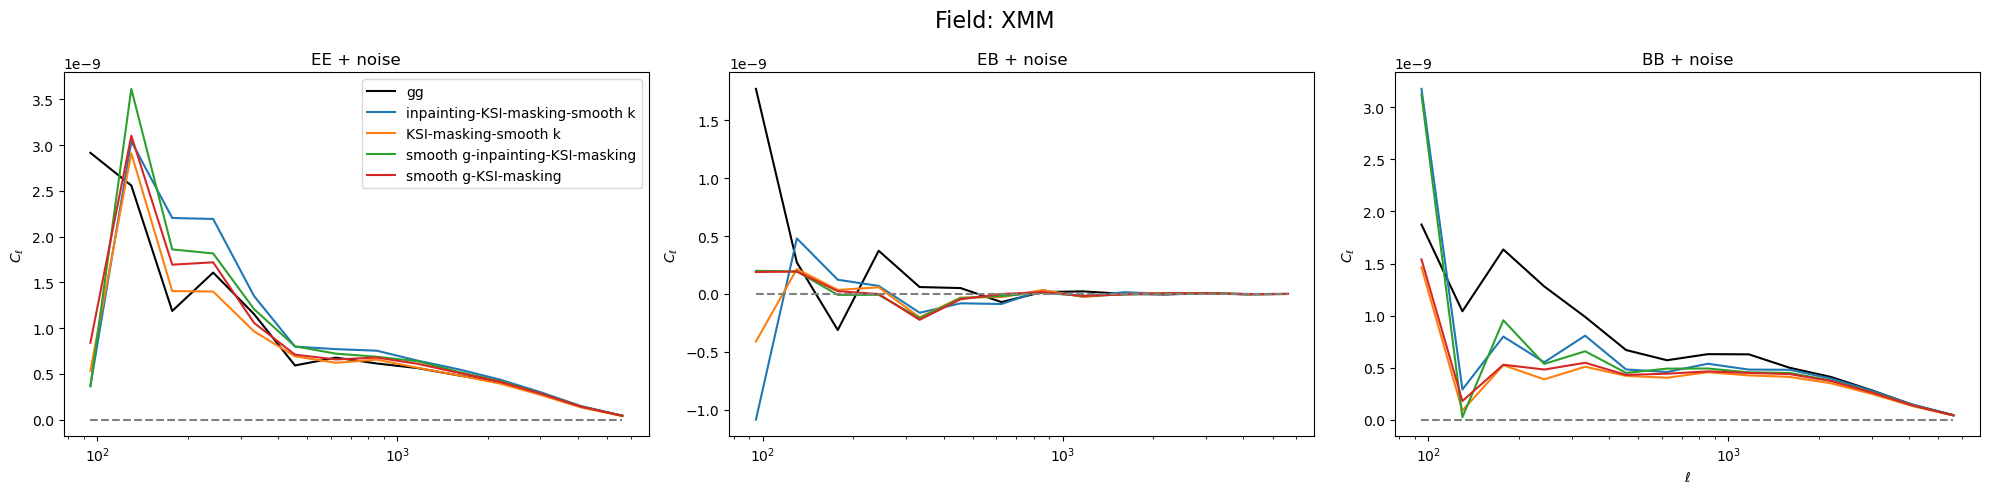

In [ ]:
xmin = stat_gg['ls'].min()
xmax = stat_gg['ls'].max()

labels = [
    'inpainting-KSI-masking-smooth k',
    'KSI-masking-smooth k',
    'smooth g-inpainting-KSI-masking',
    'smooth g-KSI-masking'
]

fig, axs = plt.subplots(1, 3, figsize=(20, 5))

# EE
axs[0].plot(stat_gg['ls'], stat_gg['EE'], label='gg', color='black')
for j, s in enumerate(stat_k):
    axs[0].plot(s['ls'], s['EE'], label=labels[j])
axs[0].hlines(0, xmin, xmax, colors='gray', linestyles='dashed')
axs[0].set_xscale('log')
axs[0].set_ylabel(r'$C_\ell$')
axs[0].set_title('EE + noise')
axs[0].legend()

# EB
axs[1].plot(stat_gg['ls'], stat_gg['EB'], label='gg', color='black')
for j, s in enumerate(stat_k):
    axs[1].plot(s['ls'], s['EB'], label=labels[j])
axs[1].hlines(0, xmin, xmax, colors='gray', linestyles='dashed')
axs[1].set_xscale('log')
axs[1].set_ylabel(r'$C_\ell$')
axs[1].set_title('EB + noise')
# axs[1].legend()

# BB
axs[2].plot(stat_gg['ls'], stat_gg['BB'], label='gg', color='black')
for j, s in enumerate(stat_k):
    axs[2].plot(s['ls'], s['BB'], label=labels[j])
axs[2].hlines(0, xmin, xmax, colors='gray', linestyles='dashed')
axs[2].set_xscale('log')
axs[2].set_ylabel(r'$C_\ell$')
axs[2].set_xlabel(r'$\ell$')
axs[2].set_title('BB + noise')
# axs[2].legend()

fig.suptitle(f'Field: {field}', fontsize=16)
plt.tight_layout()
plt.savefig(f'comp_fig/{field}_kk_gg_comp.pdf')
plt.show()

# kk VS gg, noise subtracted

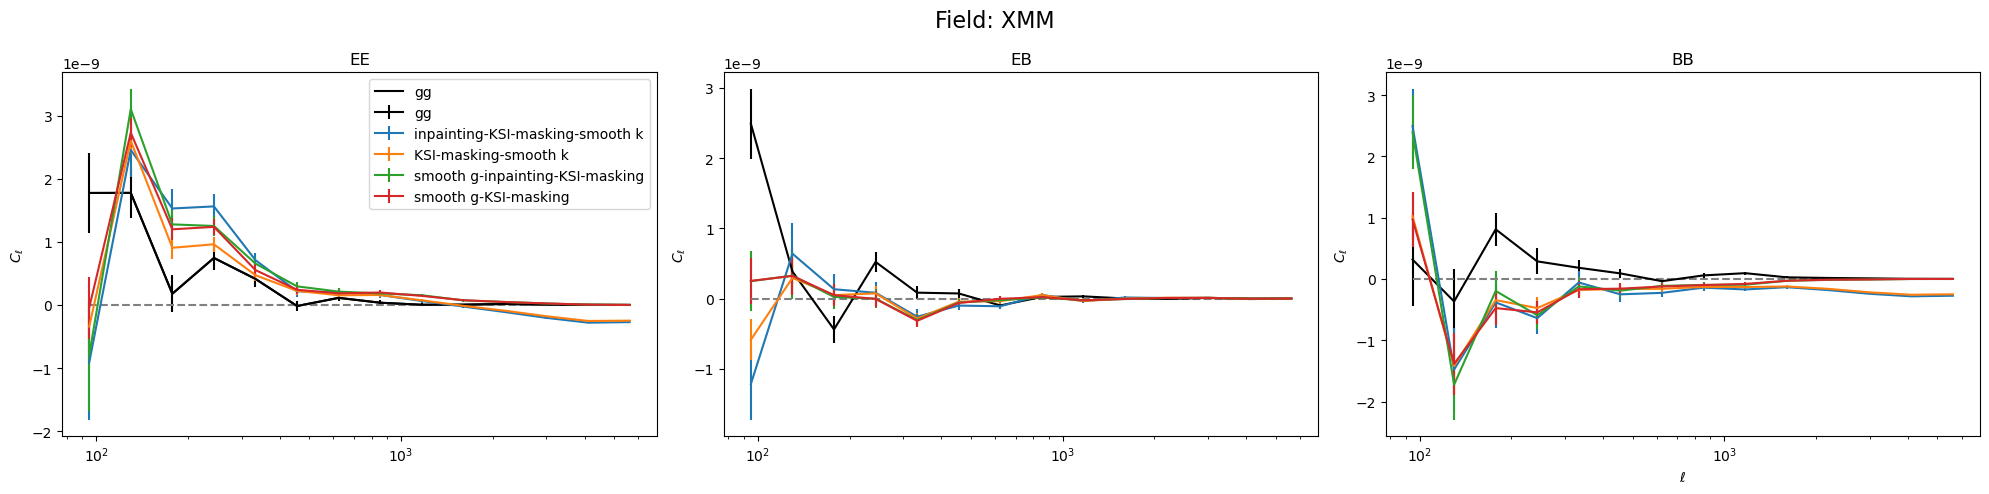

In [9]:
xmin = stat_gg['ls'].min()
xmax = stat_gg['ls'].max()

labels = [
    'inpainting-KSI-masking-smooth k',
    'KSI-masking-smooth k',
    'smooth g-inpainting-KSI-masking',
    'smooth g-KSI-masking'
]
fig, axs = plt.subplots(1, 3, figsize=(20, 5))

# EE
axs[0].plot(stat_gg['ls'], stat_gg['EE'] - stat_gg['EE_rm'], label='gg', color='black')
axs[0].errorbar(stat_gg['ls'], stat_gg['EE'] - stat_gg['EE_rm'], stat_gg['EE_std'], label='gg', color='black')
for j, s in enumerate(stat_k):
    # axs[0].plot(s['ls'], s['EE'] - s['EE_rm'], label=labels[j])
    axs[0].errorbar(s['ls'], s['EE'] - s['EE_rm'], s['EE_std'], label=labels[j])
axs[0].hlines(0, xmin, xmax, colors='gray', linestyles='dashed')
axs[0].set_xscale('log')
axs[0].set_ylabel(r'$C_\ell$')
axs[0].set_title('EE')
axs[0].legend()

# EB
# axs[1].plot(stat_gg['ls'], stat_gg['EB'] - stat_gg['EB_rm'], label='gg', color='black')
axs[1].errorbar(stat_gg['ls'], stat_gg['EB'] - stat_gg['EB_rm'], stat_gg['EB_std'], label='gg', color='black')
for j, s in enumerate(stat_k):
    # axs[1].plot(s['ls'], s['EB'] - s['EB_rm'], label=labels[j])
    axs[1].errorbar(s['ls'], s['EB'] - s['EB_rm'], s['EB_std'], label=labels[j])
axs[1].hlines(0, xmin, xmax, colors='gray', linestyles='dashed')
axs[1].set_xscale('log')
axs[1].set_ylabel(r'$C_\ell$')
axs[1].set_title('EB')
# axs[1].legend()

# BB
# axs[2].plot(stat_gg['ls'], stat_gg['BB'] - stat_gg['BB_rm'], label='gg', color='black')
axs[2].errorbar(stat_gg['ls'], stat_gg['BB'] - stat_gg['BB_rm'], stat_gg['BB_std'], label='gg', color='black')

for j, s in enumerate(stat_k):
    # axs[2].plot(s['ls'], s['BB'] - s['BB_rm'], label=labels[j])
    axs[2].errorbar(s['ls'], s['BB'] - s['BB_rm'], s['BB_std'], label=labels[j])
axs[2].hlines(0, xmin, xmax, colors='gray', linestyles='dashed')
axs[2].set_xscale('log')
axs[2].set_ylabel(r'$C_\ell$')
axs[2].set_xlabel(r'$\ell$')
axs[2].set_title('BB')
# axs[2].legend()

fig.suptitle(f'Field: {field}', fontsize=16)
plt.tight_layout()
# plt.savefig(f'comp_fig/{field}_kk_gg_comp.pdf')
plt.show()

# real VS mock

In [10]:
stat_k_mock[0]

{'ls': array([  94.761577  ,  129.73233491,  177.6086812 ,  243.15328681,
         332.88643598,  455.73465495,  623.91871002,  854.16931209,
        1169.39146397, 1600.94301758, 2191.75410844, 3000.59778462,
        4107.93666607, 5623.92725174]),
 'EE': array([1.64166944e-09, 2.12579106e-09, 1.36218339e-09, 8.55540293e-10,
        9.78252838e-10, 6.25081706e-10, 6.02493631e-10, 7.19601463e-10,
        5.47806488e-10, 4.83959569e-10, 3.90012962e-10, 2.59602909e-10,
        1.30216995e-10, 3.91432294e-11]),
 'EB': array([-5.97708310e-10, -4.50262957e-10, -4.24268420e-10,  2.69571460e-10,
         1.50099914e-10, -3.59866827e-11, -2.25458022e-11, -5.69272959e-12,
        -2.66363949e-11, -1.56406890e-11, -3.33737313e-12,  1.82217912e-13,
         5.25098972e-13, -7.59862953e-13]),
 'BE': array([1.07373855e-09, 6.78307629e-10, 7.11286582e-10, 7.99365534e-10,
        4.68662046e-10, 4.26126805e-10, 4.85632465e-10, 4.48110739e-10,
        4.47572848e-10, 4.04743362e-10, 3.61532024e-10, 2.

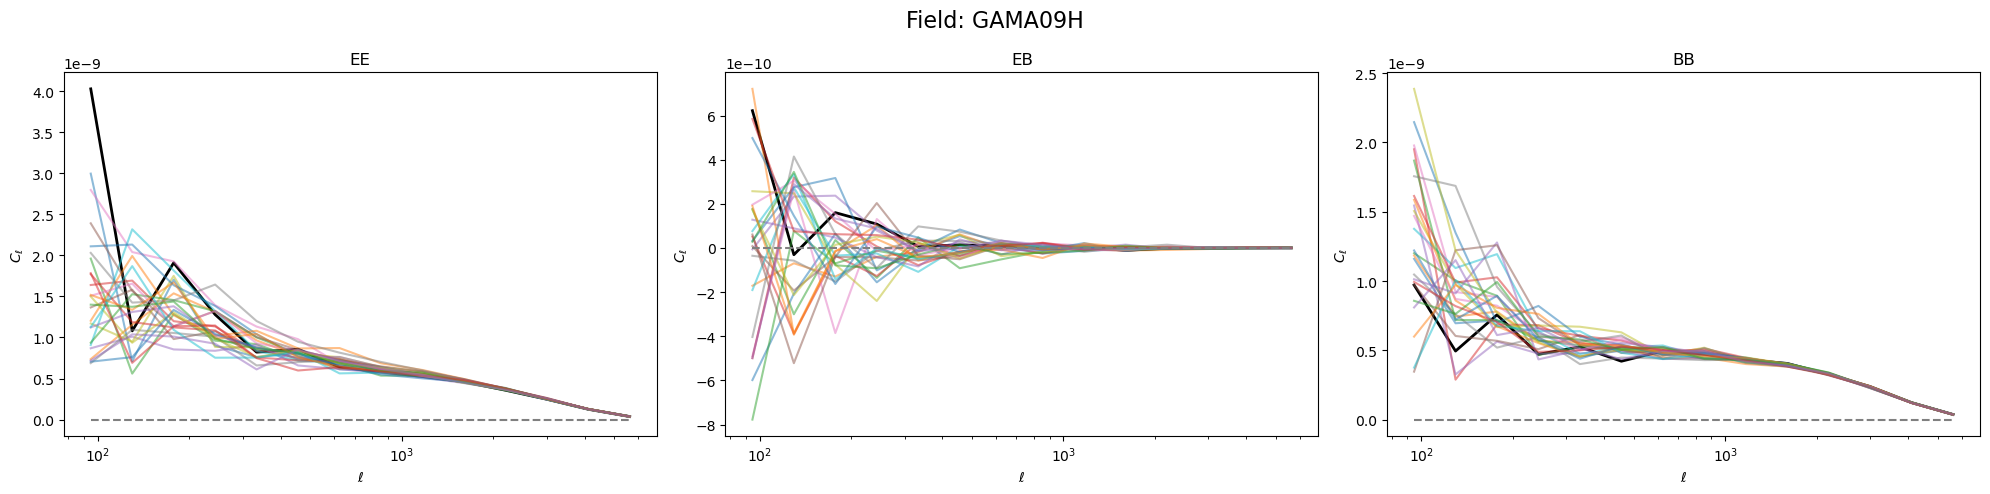

In [11]:
k_real = stat_k[1]
xmin = k_real['ls'].min()
xmax = k_real['ls'].max()

fig, axs = plt.subplots(1, 3, figsize=(20, 5))

axs[0].plot(k_real['ls'], k_real['EE'], label='k', color='black', linewidth=2)
for i in range(25):
    axs[0].plot(stat_k_mock[i]['ls'], stat_k_mock[i]['EE'], label=f'k cone{i+1}', alpha=0.5)
# EE
axs[0].hlines(0, xmin, xmax, colors='gray', linestyles='dashed')
axs[0].set_xscale('log')
axs[0].set_xlabel(r'$\ell$')
axs[0].set_ylabel(r'$C_\ell$')
axs[0].set_title('EE')
# axs[0].legend()

# EB
axs[1].plot(k_real['ls'], k_real['EB'], label='k', color='black', linewidth=2)
for i in range(25):
    axs[1].plot(stat_k_mock[i]['ls'], stat_k_mock[i]['EB'], label=f'k cone{i+1}', alpha=0.5)
axs[1].hlines(0, xmin, xmax, colors='gray', linestyles='dashed')
axs[1].set_xscale('log')
axs[1].set_xlabel(r'$\ell$')
axs[1].set_ylabel(r'$C_\ell$')
axs[1].set_title('EB')
# axs[1].legend()

# BB
axs[2].plot(k_real['ls'], k_real['BB'], label='k', color='black', linewidth=2)
for i in range(25):
    axs[2].plot(stat_k_mock[i]['ls'], stat_k_mock[i]['BB'], label=f'k cone{i+1}', alpha=0.5)
axs[2].hlines(0, xmin, xmax, colors='gray', linestyles='dashed')
axs[2].set_xscale('log')
axs[2].set_ylabel(r'$C_\ell$')
axs[2].set_xlabel(r'$\ell$')
axs[2].set_title('BB')
# axs[2].legend()

fig.suptitle(f'Field: {field}', fontsize=16)
plt.tight_layout()
# plt.savefig(f'comp_fig/{field}_kk_gg_comp.pdf')
plt.show()

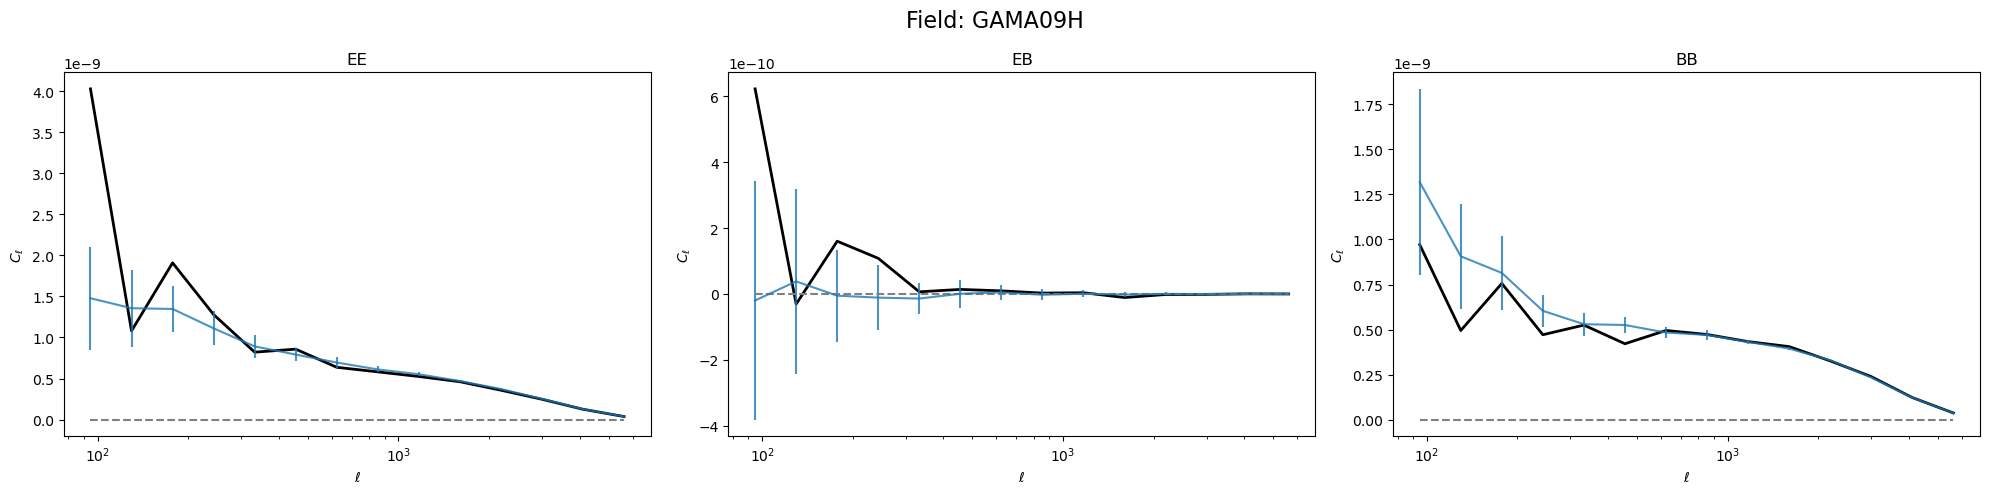

In [12]:
k_real = stat_k[1]
xmin = k_real['ls'].min()
xmax = k_real['ls'].max()


fig, axs = plt.subplots(1, 3, figsize=(20, 5))

axs[0].plot(k_real['ls'], k_real['EE'], label='k', color='black', linewidth=2)
EE_ar = [stat_k_mock[i]['EE'] for i in range(25)]
axs[0].errorbar(stat_k_mock[0]['ls'], np.average(EE_ar, axis=0), yerr=np.std(EE_ar, axis=0), label='k average', alpha=0.8)

# EE
axs[0].hlines(0, xmin, xmax, colors='gray', linestyles='dashed')
axs[0].set_xscale('log')
axs[0].set_xlabel(r'$\ell$')
axs[0].set_ylabel(r'$C_\ell$')
axs[0].set_title('EE')
# axs[0].legend()

# EB
axs[1].plot(k_real['ls'], k_real['EB'], label='k', color='black', linewidth=2)
EB_ar = [stat_k_mock[i]['EB'] for i in range(25)]
axs[1].errorbar(stat_k_mock[0]['ls'], np.average(EB_ar, axis=0), yerr=np.std(EB_ar, axis=0), label='k average', alpha=0.8)
axs[1].hlines(0, xmin, xmax, colors='gray', linestyles='dashed')
axs[1].set_xscale('log')
axs[1].set_xlabel(r'$\ell$')
axs[1].set_ylabel(r'$C_\ell$')
axs[1].set_title('EB')
# axs[1].legend()

# BB
axs[2].plot(k_real['ls'], k_real['BB'], label='k', color='black', linewidth=2)
BB_ar = [stat_k_mock[i]['BB'] for i in range(25)]
axs[2].errorbar(stat_k_mock[0]['ls'], np.average(BB_ar, axis=0), yerr=np.std(BB_ar, axis=0), label='k average', alpha=0.8)

axs[2].hlines(0, xmin, xmax, colors='gray', linestyles='dashed')
axs[2].set_xscale('log')
axs[2].set_ylabel(r'$C_\ell$')
axs[2].set_xlabel(r'$\ell$')
axs[2].set_title('BB')
# axs[2].legend()

fig.suptitle(f'Field: {field}', fontsize=16)
plt.tight_layout()
# plt.savefig(f'comp_fig/{field}_kk_gg_comp.pdf')
plt.show()